<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_IntrusionDetection_Cotrupi2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum-kernel SVM for network intrusion detection: Cotrupi and Callahan (2025) step by step

This notebook re-implements, runs and checks the method of

> Mary L. Cotrupi and Brian R. Callahan, "Towards Practical Quantum Kernels for Network Intrusion Detection",
> *Proceedings of the AAAI Fall Symposium Series (FSS-25)*, vol. 7, no. 1, pp. 339-342, 2025.
> DOI 10.1609/aaaiss.v7i1.36903

The paper is a four-page preview. It publishes no code and no hyper-parameters, so everything below is written from its
description: a quantum kernel (built with the QuASK library) feeds a scikit-learn `SVC`; the pipeline is tested on four
attacks of an intrusion-detection dataset, on a noiseless simulator, on a classical RBF kernel and on real IBM hardware.

**What the notebook does.** For each of the four attacks of the paper (SSH brute force, botnet, Slowloris DoS, LOIC HTTP
DDoS) it downloads the real network flows, removes constant and collinear columns, lets XGBoost pick the eight most useful
features, draws a balanced sample of benign and attack flows (60 flows for the "hardware" comparison, 1,000 for the
simulator comparison), encodes each flow into an 8-qubit ZZ feature map, computes the fidelity kernel
$K(x,y)=|\langle\phi(x)|\phi(y)\rangle|^2$ and trains an SVM on it. A scikit-learn RBF SVM (the paper's classical
benchmark), a random forest and a linear SVM are trained on exactly the same inputs. Because no IBM quantum computer is
available here, the "hardware" results of the paper are replaced by an **emulation of a 127-qubit IBM Eagle device**
(`FakeSherbrooke` noise model, transpiled circuits, density-matrix simulation, finite shots); this is clearly labelled
and is *not* a hardware measurement.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned Qiskit versions; if Colab asks you to restart the session, restart and run all again. No GPU, no quantum-cloud
account and no Hugging Face token are needed (the dataset mirror is public); a token in Colab Secrets is only used if you
have one.

**Runtime.** `FAST_MODE = True` (3 data draws at n = 60, 2 at n = 1,000, a noisy-device emulation of one attack with 20
flows) finishes in about 10 minutes. `FAST_MODE = False` (10 draws, noisy-device emulation of all four attacks with 60
flows each, 10 shot-noise repeats) took 67 minutes on a shared laptop CPU (54 minutes of them for the emulated device, about
0.5 s per circuit and 6,800 circuits); the committed notebook contains the output of this full run (`FAST_MODE = False`).

**What you get at the end.** Accuracy, precision, recall and F1 per attack, confusion matrices, the paper's Figures 2 and 3
redrawn next to your numbers, the quantum circuits that were executed, and a table that puts every number of the paper beside
the notebook's with a verdict per claim ("reproduced" / "not reached" / "exceeded" / "cannot be checked").

## The paper in one page

**Problem.** Detect network attacks (anomalous versus benign flows) with a hybrid quantum-classical model that is small
enough to run on today's noisy quantum computers.

**Decision.** For each of four attacks separately: benign (0) versus attack (1).

**Method.** QuASK quantum kernel (inner products of encoded states estimated by the overlap or the swap test, Fig. 1) plus
scikit-learn `SVC` on the precomputed kernel matrix. The classical benchmark is scikit-learn's default RBF `SVC`; the noiseless
benchmark is Qiskit Aer; the hardware is the 127-qubit IBM Quantum System One at Rensselaer Polytechnic Institute
(`ibm_rensselaer`).

**Data.** BCCC-CSE-CIC-IDS2018 (a re-extraction of CSE-CIC-IDS2018 with 300+ features and 46 million records). Four attacks:
brute-force SSH ("BF SSH"), botnet, Slowloris DoS and LOIC HTTP DDoS.

**Preprocessing.** Remove missing columns and rows and highly collinear features, use XGBoost to select the top eight features
(eight qubits), randomly sample 30 attack and 30 benign points (1 : 1), 8 : 2 train : test split.

**Claims.**

| Claim | Where | Value |
|---|---|---|
| Average accuracy on the quantum computer (n = 60, ten hardware iterations) | abstract, Fig. 2 | about 85 % (mean line of Fig. 2 at 0.84), small spread between runs |
| Noiseless simulator and RBF kernel, n = 60 | Fig. 2 | simulator mean about 0.96, RBF mean about 0.93 |
| Noiseless simulator versus RBF, n = 1,000 | Fig. 3, text | 93.5 % versus 93.7 % average accuracy |
| Per attack at n = 1,000 | Fig. 3 (read off the plot, +-0.01) | simulator 0.997 / 0.860 / 0.890 / 0.993, RBF 0.997 / 0.891 / 0.916 / 0.947 (BF SSH / Botnet / Slowloris / LOIC) |
| Per attack at n = 60 | Fig. 2 (read off the plot, +-0.01) | simulator 1.00 / 0.89 / 0.94 / 1.00, RBF 0.98 / 0.93 / 0.86 / 0.95, hardware 0.93 / 0.76 / 0.87 / 0.80 |

The paper's numbers are only stated in the text for the 85 % hardware mean and the 93.5 % / 93.7 % pair; the per-attack numbers are
read off the published figures (the two plots were extracted from the PDF and read by eye), so they carry about +-0.01 of reading error.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | BCCC-CSE-CIC-IDS2018 (York University, 300+ NTLFlowLyzer features, 46 M records) | Original **CSE-CIC-IDS2018** (CICFlowMeter, 77 features) from the public Hugging Face mirror `iraklislf/cic-ids2018-dataset`; the BCCC re-extraction is not mirrored publicly. Attack and benign flows of the same capture day. |
| Four attacks | BF SSH, Botnet, DoS Slowloris, DDoS LOIC HTTP | the same four (labels `SSH-Bruteforce`, `Bot`, `DoS attacks-Slowloris`, `DDoS attacks-LOIC-HTTP`) |
| Cleaning | missing columns/rows, collinear data removed | NaN/inf rows dropped, constant columns dropped, columns with absolute correlation > 0.95 dropped (`# CHOICE:` threshold) |
| Feature selection | XGBoost, top 8 | XGBoost gain importance, top 8, fitted on a *selection pool* of 2,000 + 2,000 flows that is disjoint from every evaluated sample (no test leakage) |
| Sample size | n = 60 (30 + 30) and n = 1,000 | the same, drawn at random without replacement; repeated for several draws (mean +- std) |
| Split | 8 : 2 train : test | stratified 80 : 20 |
| Scaling | not stated | signed log1p, z-score, MinMax to [0, pi], all fitted on the training split only, test angles clipped (`# CHOICE:`) |
| Feature map / ansatz | "kernel encodes the data", QuASK, not specified | `zz_feature_map(8, reps=2, entanglement="linear")` with an angle bandwidth (`# CHOICE:`) |
| Bandwidth | not stated | angle scale tuned by 3-fold cross-validation on the training split only (`# CHOICE:`) |
| Kernel estimator | overlap (compute-uncompute) or swap test | overlap test, exact for the noiseless simulator (statevector), finite shots for the device emulation |
| SVM | scikit-learn `SVC` | `SVC(kernel="precomputed", C=1)` (library default `C`) |
| Classical benchmark | scikit-learn RBF `SVC`, defaults | `SVC(kernel="rbf")`, defaults, on the same 8 angle-scaled features |
| Noiseless simulator | Qiskit Aer | exact statevector kernel (vectorised NumPy, asserted equal to Qiskit's `FidelityStatevectorKernel` and to Aer) |
| Quantum computer | `ibm_rensselaer`, 127 qubits, ten iterations | **not available**: Aer density-matrix simulation with the `FakeSherbrooke` noise model (127-qubit Eagle, same family), circuits transpiled to its native gates, 1,024 shots, ten shot-noise repeats; optional real run if `IBM_TOKEN` is set |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and xgboost.
# The pip line runs on Colab (or wherever qiskit-aer is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_aer") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc xgboost huggingface_hub pyarrow
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-aer already present; skipping pip install.")

qiskit-aer already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo (about 10 min). False: the full budgets below (about 70 min on a shared CPU).
SEED      = 42              # CHOICE: the paper gives no seed
N_QUBITS  = 8               # paper: top-8 features = 8 qubits
N_SMALL   = 60              # paper: n = 60 (30 attack + 30 benign) for the hardware comparison
N_LARGE   = 1000            # paper: n = 1,000 for the simulator vs classical comparison
TEST_SIZE = 0.2             # paper: 8 : 2 train : test

if FAST_MODE:
    R_SMALL, R_LARGE = 3, 2             # independent random draws at n = 60 / n = 1,000 (mean +- std over draws)
    HW_N, HW_ATTACKS = 20, ["BF_SSH"]   # noisy-device emulation: flows per draw and which attacks (full run: 60 and all four)
else:
    R_SMALL, R_LARGE = 10, 10
    HW_N, HW_ATTACKS = 60, ["BF_SSH", "Botnet", "DoS_Slowloris", "DDoS_LOIC_HTTP"]
HW_T     = 10               # paper: ten hardware iterations (here: ten shot-noise repeats of the emulated device)
HW_SHOTS = 1024             # CHOICE: shots per kernel entry on the emulated device (paper: not stated)
HW_BACKEND = "FakeSherbrooke"   # 127-qubit IBM Eagle noise model; the paper used ibm_rensselaer (also Eagle, 127 qubits)
IBM_TOKEN = ""              # optional: a real IBM Quantum token makes the last experiment cell also run on real hardware

FM_REPS      = 2                      # CHOICE: ZZ feature map repetitions (paper: unspecified, "low circuit depth")
ENTANGLEMENT = "linear"               # CHOICE: nearest-neighbour ZZ pairs
BW_GRID      = [0.05, 0.1, 0.25, 0.5, 1.0]  # CHOICE: candidate angle bandwidths, tuned on the training split only
CV_FOLDS     = 3                      # CHOICE: inner cross-validation folds for the bandwidth
SVM_C        = 1.0                    # scikit-learn default (paper: "Scikit C-Support Vector Classification", no C given)

SEL_PER_CLASS  = 2000       # CHOICE: flows per class in the feature-selection pool (disjoint from the evaluated samples)
POOL_PER_CLASS = 6000       # flows per class kept from each capture-day file (everything else is discarded to save disk)
OTHER_CAP      = 1500       # other attack families of the same file kept only for the exploration plots
COLLINEAR_THRESHOLD = 0.95  # CHOICE: absolute Pearson correlation above which a column is dropped
TOP_K = N_QUBITS

DATA_DIR = "data"           # downloads are cached here; large raw files are deleted right after sampling
HF_REPO  = "iraklislf/cic-ids2018-dataset"   # public mirror of CSE-CIC-IDS2018 (CICFlowMeter version), one parquet per capture day
ATTACKS = {                 # name -> (capture-day file stem, attack label in the file)
    "BF_SSH":         ("Bruteforce-Wednesday-14-02-2018", "SSH-Bruteforce"),
    "Botnet":         ("Botnet-Friday-02-03-2018",        "Bot"),
    "DoS_Slowloris":  ("DoS1-Thursday-15-02-2018",        "DoS attacks-Slowloris"),
    "DDoS_LOIC_HTTP": ("DDoS1-Tuesday-20-02-2018",        "DDoS attacks-LOIC-HTTP"),
}
ATTACK_NAMES = list(ATTACKS)
print("FAST_MODE =", FAST_MODE, "| draws n=60:", R_SMALL, "| draws n=1000:", R_LARGE, "| emulated device:", HW_ATTACKS, "n =", HW_N)

FAST_MODE = False | draws n=60: 10 | draws n=1000: 10 | emulated device: ['BF_SSH', 'Botnet', 'DoS_Slowloris', 'DDoS_LOIC_HTTP'] n = 60


In [3]:
import os, time, json, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn, xgboost, qiskit, qiskit_aer, qiskit_machine_learning
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

from qiskit import transpile
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.library import SaveProbabilities
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals

# Hugging Face token: only used if present (the dataset mirror is public). Never printed, never stored in the notebook.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
algorithm_globals.random_seed = SEED
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | xgboost 3.4.1 | numpy 2.5.4 | pandas 3.0.6


## 1. Data: the four attacks of CSE-CIC-IDS2018

CSE-CIC-IDS2018 (Canadian Institute for Cybersecurity and the Communications Security Establishment, 2018) is a ten-day
capture of a network with benign users and scripted attackers; the traffic is converted to flow records by CICFlowMeter. The
paper uses its re-extraction **BCCC-CSE-CIC-IDS2018** (York University, 300+ features from NTLFlowLyzer), which is only
distributed through the university's download page and is not mirrored on Hugging Face. This notebook therefore uses the
original CICFlowMeter version from the public mirror `iraklislf/cic-ids2018-dataset` (one parquet file per capture day, 77 numeric
features plus the label). The four attacks of the paper sit in four capture days:

| Attack in the paper | Capture day | Label used here |
|---|---|---|
| BF SSH | Wednesday 14 Feb 2018 | `SSH-Bruteforce` (the 53 `FTP-BruteForce` flows of that day are not used) |
| Botnet | Friday 2 Mar 2018 | `Bot` |
| DoS Slowloris | Thursday 15 Feb 2018 | `DoS attacks-Slowloris` (the GoldenEye flows of that day are not used) |
| DDoS LOIC HTTP | Tuesday 20 Feb 2018 | `DDoS attacks-LOIC-HTTP` |

Every attack is a *separate binary problem* against the benign flows of its own capture day. Each parquet file is 80-100 MB,
so the cell below downloads one file at a time, keeps a random pool of 6,000 flows per class (plus a few thousand flows of the
other attack families of that day for the exploration plots) in `DATA_DIR`, and **deletes the large file immediately**. The cache
is about 6 MB in total.

In [4]:
def build_pool(name):
    # download one capture-day file, keep a seeded random pool, delete the big raw file
    out = os.path.join(DATA_DIR, f"pool_{name}.parquet")
    if os.path.exists(out):
        return out
    from huggingface_hub import hf_hub_download
    import pyarrow.parquet as pq
    stem, attack_label = ATTACKS[name]
    fn = f"data/{stem}_TrafficForML_CICFlowMeter.parquet"
    path = hf_hub_download(HF_REPO, fn, repo_type="dataset", local_dir=os.path.join(DATA_DIR, "raw"), token=HF_TOKEN or None)
    df = pq.ParquetFile(path).read().to_pandas()
    df["Label"] = df["Label"].astype(str)
    counts = df["Label"].value_counts().to_dict()
    parts = []
    for label, g in df.groupby("Label"):
        cap = POOL_PER_CLASS if label in ("Benign", attack_label) else OTHER_CAP
        parts.append(g.sample(n=min(cap, len(g)), random_state=SEED))
    pool = pd.concat(parts).reset_index(drop=True)
    pool.to_parquet(out)
    json.dump({"file": fn, "rows": int(len(df)), "n_columns": int(df.shape[1]), "label_counts": counts},
              open(os.path.join(DATA_DIR, f"meta_{name}.json"), "w"))
    del df
    os.remove(path)                      # CHOICE: free the disk space at once (the raw file is 80-100 MB)
    print(f"{name}: pool of {len(pool):,} flows saved ({os.path.getsize(out)/1e6:.1f} MB); raw file deleted")
    return out

t0 = time.time()
POOLS, META = {}, {}
for name in ATTACK_NAMES:
    p = build_pool(name)
    POOLS[name] = pd.read_parquet(p)
    META[name] = json.load(open(os.path.join(DATA_DIR, f"meta_{name}.json")))
print(f"data ready in {time.time()-t0:.0f} s")
left = [os.path.join(r, f) for r, _, fs in os.walk(DATA_DIR) for f in fs if os.path.getsize(os.path.join(r, f)) > 50e6]
print("files larger than 50 MB left in DATA_DIR:", left)

data/Bruteforce-Wednesday-14-02-2018_Tra(…): reconstructing file:   0%|          |  0.00B / 76.4MB            

data/Bruteforce-Wednesday-14-02-2018_Tra(…): downloading bytes:           |  0.00B            

BF_SSH: pool of 12,053 flows saved (1.7 MB); raw file deleted


data/Botnet-Friday-02-03-2018_TrafficFor(…): reconstructing file:   0%|          |  0.00B / 83.5MB            

data/Botnet-Friday-02-03-2018_TrafficFor(…): downloading bytes:           |  0.00B            

...

data/DoS1-Thursday-15-02-2018_TrafficFor(…): downloading bytes:           |  0.00B            

DoS_Slowloris: pool of 13,500 flows saved (2.0 MB); raw file deleted


data/DDoS1-Tuesday-20-02-2018_TrafficFor(…): reconstructing file:   0%|          |  0.00B / 89.5MB            

data/DDoS1-Tuesday-20-02-2018_TrafficFor(…): downloading bytes:           |  0.00B            

DDoS_LOIC_HTTP: pool of 12,000 flows saved (1.4 MB); raw file deleted
data ready in 47 s
files larger than 50 MB left in DATA_DIR: []


## 2. Cleaning, binary labels and the eight XGBoost features

For each attack the pool is split into two **disjoint** parts per class: a *selection pool* (2,000 benign + 2,000 attack flows)
and an *experiment pool* (the remaining flows, from which every evaluated sample is drawn). The paper selects its features on the
whole dataset subset before sampling; selecting on a pool that never contributes a test point does the same job without any
leakage. On the selection pool we

1. drop rows with missing or infinite values and constant columns,
2. drop highly collinear columns (absolute Pearson correlation > 0.95 with a column that is kept; `# CHOICE:` threshold),
3. fit an XGBoost classifier (100 trees, depth 3) and keep the **eight** columns with the highest gain importance.

The experiment pool is then restricted to those eight columns. CICFlowMeter features are heavy-tailed (durations in
microseconds, byte counts), so every sample later goes through a signed `log1p` before standardisation (`# CHOICE:` the paper
does not describe its scaling).

In [5]:
FEATURES = [c for c in POOLS[ATTACK_NAMES[0]].columns if c != "Label"]
print(len(FEATURES), "numeric feature columns in the CICFlowMeter files")

def slog(a):                      # CHOICE: signed log1p to tame heavy tails (paper: scaling not described)
    return np.sign(a) * np.log1p(np.abs(a))

SEL, EXP, OTHERS, TOP = {}, {}, {}, {}
sel_rows = []
for name in ATTACK_NAMES:
    attack_label = ATTACKS[name][1]
    pool = POOLS[name].copy()
    pool[FEATURES] = pool[FEATURES].astype("float64").replace([np.inf, -np.inf], np.nan)
    n0 = len(pool)
    pool = pool.dropna(subset=FEATURES).reset_index(drop=True)
    pool["y"] = (pool["Label"] == attack_label).astype(int)
    main = pool[pool["Label"].isin(["Benign", attack_label])].reset_index(drop=True)
    OTHERS[name] = pool[~pool["Label"].isin(["Benign", attack_label])].reset_index(drop=True)
    # disjoint selection / experiment pools, per class
    r = np.random.default_rng(SEED)
    sel_idx, exp_idx = [], []
    for y in (0, 1):
        idx = r.permutation(np.where(main["y"].values == y)[0])
        sel_idx += list(idx[:SEL_PER_CLASS]); exp_idx += list(idx[SEL_PER_CLASS:])
    sel = main.iloc[sel_idx].reset_index(drop=True); exp = main.iloc[exp_idx].reset_index(drop=True)
    # 1. constant columns
    Xs = sel[FEATURES]
    keep = [c for c in FEATURES if Xs[c].nunique() > 1]
    # 2. collinear columns
    corr = Xs[keep].corr().abs().fillna(0)
    kept = []
    for c in keep:
        if all(corr.loc[c, k] <= COLLINEAR_THRESHOLD for k in kept):
            kept.append(c)
    # 3. XGBoost top-8 by gain
    xgb = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, importance_type="gain", random_state=SEED,
                        n_jobs=2, eval_metric="logloss")
    xgb.fit(Xs[kept].values, sel["y"].values)
    imp = pd.Series(xgb.feature_importances_, index=kept).sort_values(ascending=False)
    top = list(imp.index[:TOP_K])
    SEL[name], EXP[name], TOP[name] = sel, exp, top
    sel_rows.append({"attack": name, "rows dropped (NaN/inf)": n0 - len(pool), "constant cols": len(FEATURES) - len(keep),
                     "collinear cols": len(keep) - len(kept), "kept for XGBoost": len(kept),
                     "selection pool": len(sel), "experiment pool (attack / benign)": f"{int(exp['y'].sum())} / {int((1-exp['y']).sum())}"})
display(pd.DataFrame(sel_rows).set_index("attack"))
for name in ATTACK_NAMES:
    print(f"{name:15s} top-{TOP_K} features:", ", ".join(TOP[name]))

77 numeric feature columns in the CICFlowMeter files


,rows dropped (NaN/inf),constant cols,collinear cols,kept for XGBoost,selection pool,experiment pool (attack / benign)
attack,,,,,,
BF_SSH,0,10,26,41,4000,4000 / 4000
Botnet,0,10,24,43,4000,4000 / 4000
DoS_Slowloris,0,10,24,43,4000,4000 / 4000
DDoS_LOIC_HTTP,0,10,28,39,4000,4000 / 4000


BF_SSH          top-8 features: Fwd Seg Size Min, Fwd Act Data Packets, Bwd Packet Length Max, Flow Packets/s, URG Flag Count, Flow Duration, Bwd IAT Min, Init Bwd Win Bytes
Botnet          top-8 features: RST Flag Count, Packet Length Std, Flow Duration, Bwd Packet Length Max, Flow IAT Mean, Bwd Packet Length Mean, Flow Bytes/s, Fwd Act Data Packets
DoS_Slowloris   top-8 features: Fwd Seg Size Min, Flow Bytes/s, Flow IAT Std, Packet Length Std, Flow Duration, Bwd Packets/s, FIN Flag Count, Flow IAT Min
DDoS_LOIC_HTTP  top-8 features: Fwd Packet Length Max, Init Bwd Win Bytes, Flow Duration, Flow IAT Max, Init Fwd Win Bytes, Flow IAT Std, Fwd IAT Std, Idle Mean


## Dataset Exploration and Visualisation

Everything in this section uses the real flows of the capture days; nothing is simulated. We print the shape, the feature names
and the original label counts of each capture day, plot the class distribution, and draw labelled 2-D scatter plots of real
flows: first the raw PCA coordinates of an n = 1,000 sample (PCA fitted on the training split only), then the same
coordinates scaled to [0, pi] (the range of the rotation angles), then the first two *actual* encoding angles (the two most
important XGBoost features after scaling), and finally the multi-class view that keeps the other attack families of each capture day.

In [6]:
rows = []
for name in ATTACK_NAMES:
    m = META[name]
    rows.append({"attack": name, "file": m["file"].split("/")[-1], "rows in file": m["rows"], "columns": m["n_columns"],
                 "original labels (rows in the whole file)": m["label_counts"]})
pd.set_option("display.max_colwidth", 140)
display(pd.DataFrame(rows).set_index("attack"))
print("\nFeature names (%d numeric columns, same for every file):" % len(FEATURES))
print(", ".join(FEATURES))
print()
for name in ATTACK_NAMES:
    print(f"{name:15s} pool shape {POOLS[name].shape}  -> selection pool {SEL[name].shape}, experiment pool {EXP[name].shape}; "
          f"original labels in the pool: {POOLS[name]['Label'].value_counts().to_dict()}")

,file,rows in file,columns,original labels (rows in the whole file)
attack,,,,
BF_SSH,Bruteforce-Wednesday-14-02-2018_TrafficForML_CICFlowMeter.parquet,619346,78,"{'Benign': 525245, 'SSH-Bruteforce': 94048, 'FTP-BruteForce': 53}"
Botnet,Botnet-Friday-02-03-2018_TrafficForML_CICFlowMeter.parquet,771587,78,"{'Benign': 627052, 'Bot': 144535}"
DoS_Slowloris,DoS1-Thursday-15-02-2018_TrafficForML_CICFlowMeter.parquet,794812,78,"{'Benign': 743498, 'DoS attacks-GoldenEye': 41406, 'DoS attacks-Slowloris': 9908}"
DDoS_LOIC_HTTP,DDoS1-Tuesday-20-02-2018_TrafficForML_CICFlowMeter.parquet,954846,78,"{'DDoS attacks-LOIC-HTTP': 575364, 'Benign': 379482}"



Feature names (77 numeric columns, same for every file):
Protocol, Flow Duration, Total Fwd Packets, Total Backward Packets, Fwd Packets Length Total, Bwd Packets Length Total, Fwd Packet Length Max, Fwd Packet Length Min, Fwd Packet Length Mean, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT Total, Fwd IAT Mean, Fwd IAT Std, Fwd IAT Max, Fwd IAT Min, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Std, Bwd IAT Max, Bwd IAT Min, Fwd PSH Flags, Bwd PSH Flags, Fwd URG Flags, Bwd URG Flags, Fwd Header Length, Bwd Header Length, Fwd Packets/s, Bwd Packets/s, Packet Length Min, Packet Length Max, Packet Length Mean, Packet Length Std, Packet Length Variance, FIN Flag Count, SYN Flag Count, RST Flag Count, PSH Flag Count, ACK Flag Count, URG Flag Count, CWE Flag Count, ECE Flag Count, Down/Up Ratio, Avg Packet Size, Avg Fwd Segment Size, Av

BF_SSH          pool shape (12053, 78)  -> selection pool (4000, 79), experiment pool (8000, 79); original labels in the pool: {'Benign': 6000, 'SSH-Bruteforce': 6000, 'FTP-BruteForce': 53}
Botnet          pool shape (12000, 78)  -> selection pool (4000, 79), experiment pool (8000, 79); original labels in the pool: {'Benign': 6000, 'Bot': 6000}
DoS_Slowloris   pool shape (13500, 78)  -> selection pool (4000, 79), experiment pool (8000, 79); original labels in the pool: {'Benign': 6000, 'DoS attacks-Slowloris': 6000, 'DoS attacks-GoldenEye': 1500}
DDoS_LOIC_HTTP  pool shape (12000, 78)  -> selection pool (4000, 79), experiment pool (8000, 79); original labels in the pool: {'Benign': 6000, 'DDoS attacks-LOIC-HTTP': 6000}


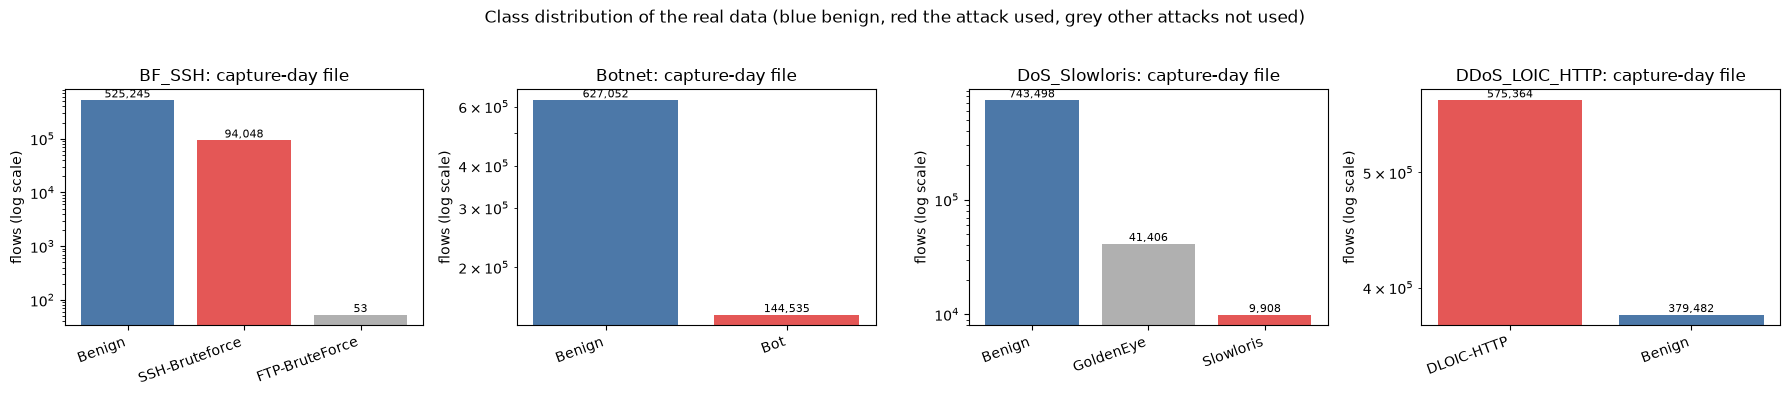

In [7]:
# class distribution of the real data: original labels of each capture-day file, and the balanced pools used here
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, name in zip(axes, ATTACK_NAMES):
    cnt = pd.Series(META[name]["label_counts"]).sort_values(ascending=False)
    colors = ["#4c78a8" if k == "Benign" else ("#e45756" if k == ATTACKS[name][1] else "#b0b0b0") for k in cnt.index]
    ax.bar(range(len(cnt)), cnt.values, color=colors)
    ax.set_xticks(range(len(cnt))); ax.set_xticklabels([k.replace("DoS attacks-", "").replace("DDoS attacks-", "") for k in cnt.index], rotation=20, ha="right")
    ax.set_yscale("log"); ax.set_title(f"{name}: capture-day file"); ax.set_ylabel("flows (log scale)")
    for i, v in enumerate(cnt.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.suptitle("Class distribution of the real data (blue benign, red the attack used, grey other attacks not used)", y=1.03)
plt.tight_layout(); plt.show()

BF_SSH          n = 1000: train (800, 8), test (200, 8); attack share train 0.50 / test 0.50
Botnet          n = 1000: train (800, 8), test (200, 8); attack share train 0.50 / test 0.50
DoS_Slowloris   n = 1000: train (800, 8), test (200, 8); attack share train 0.50 / test 0.50
DDoS_LOIC_HTTP  n = 1000: train (800, 8), test (200, 8); attack share train 0.50 / test 0.50


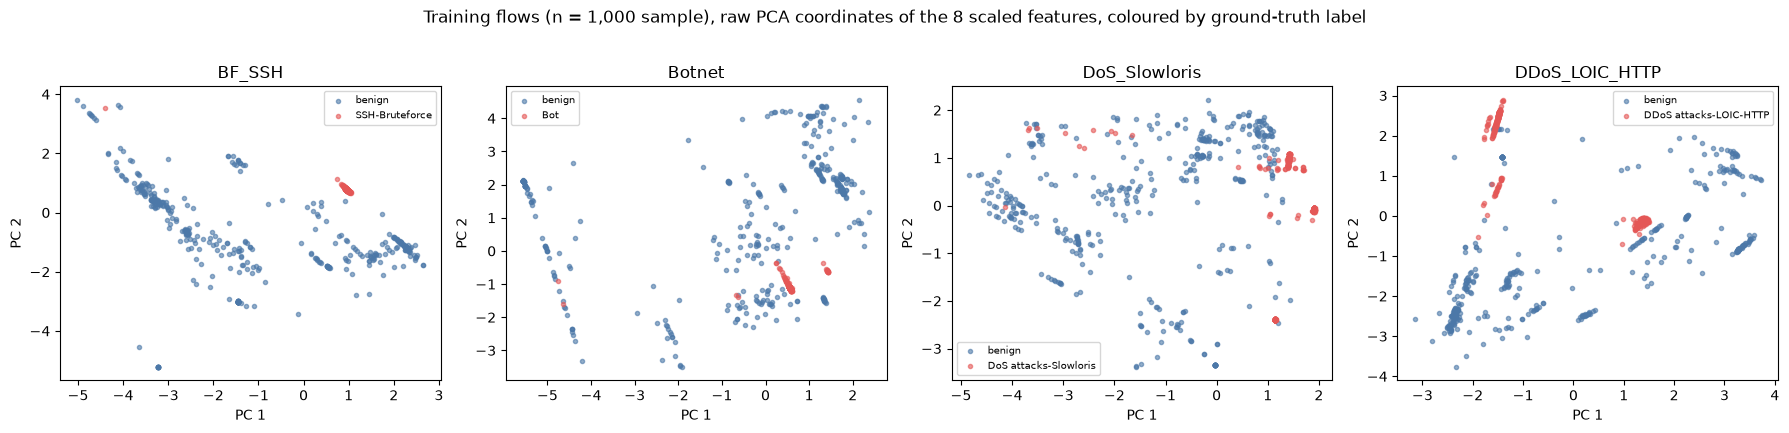

In [8]:
# preprocessing used by every experiment: eight XGBoost features -> signed log1p -> z-score -> MinMax [0, pi]; fitted on the TRAIN split only
def draw_sample(name, n, draw):
    r = np.random.default_rng(SEED + 1000 * draw + 17 * ATTACK_NAMES.index(name) + n)
    exp = EXP[name]
    idx = []
    for y in (0, 1):
        pool_idx = np.where(exp["y"].values == y)[0]
        idx += list(r.choice(pool_idx, n // 2, replace=False))          # 1 : 1 anomaly : benign as in the paper
    X = slog(exp.iloc[idx][TOP[name]].values); y = exp.iloc[idx]["y"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED + draw)
    zs = StandardScaler().fit(Xtr)
    Ztr, Zte = zs.transform(Xtr), zs.transform(Xte)
    mm = MinMaxScaler((0, np.pi)).fit(Ztr)
    Atr, Ate = mm.transform(Ztr), np.clip(mm.transform(Zte), 0, np.pi)      # test angles clipped to [0, pi]
    return dict(Ztr=Ztr, Zte=Zte, Atr=Atr, Ate=Ate, ytr=ytr, yte=yte)

d = {name: draw_sample(name, N_LARGE, 0) for name in ATTACK_NAMES}
for name in ATTACK_NAMES:
    print(f"{name:15s} n = {N_LARGE}: train {d[name]['Atr'].shape}, test {d[name]['Ate'].shape}; attack share train {d[name]['ytr'].mean():.2f} / test {d[name]['yte'].mean():.2f}")

def scatter4(get_xy, title, xlabel, ylabel, lim=None):
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
    for ax, name in zip(axes, ATTACK_NAMES):
        x, y, lab = get_xy(name)
        for yy, col, txt in ((0, "#4c78a8", "benign"), (1, "#e45756", ATTACKS[name][1])):
            ax.scatter(x[lab == yy], y[lab == yy], s=9, alpha=0.6, c=col, label=txt)
        ax.set_title(name); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.legend(fontsize=7, loc="best")
        if lim: ax.set_xlim(*lim); ax.set_ylim(*lim)
    plt.suptitle(title, y=1.02); plt.tight_layout(); plt.show()

# (a) raw PCA coordinates, PCA fitted on the training split only
PCAS = {name: PCA(n_components=2, random_state=SEED).fit(d[name]["Ztr"]) for name in ATTACK_NAMES}
scatter4(lambda n: (*PCAS[n].transform(d[n]["Ztr"]).T, d[n]["ytr"]),
         "Training flows (n = 1,000 sample), raw PCA coordinates of the 8 scaled features, coloured by ground-truth label", "PC 1", "PC 2")

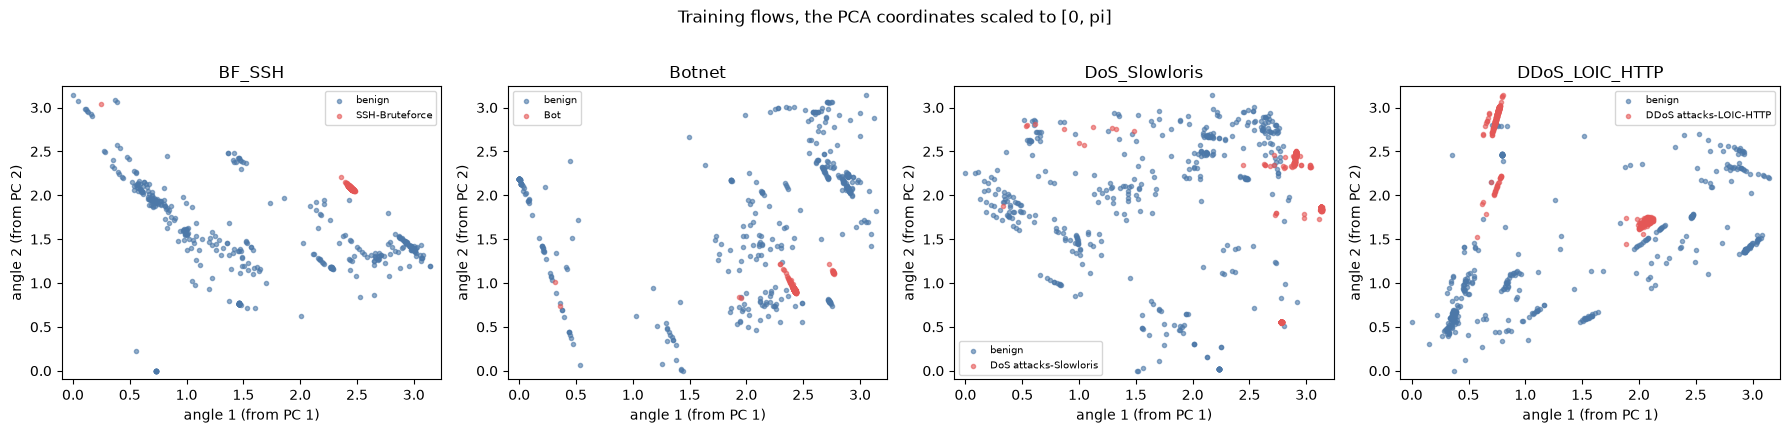

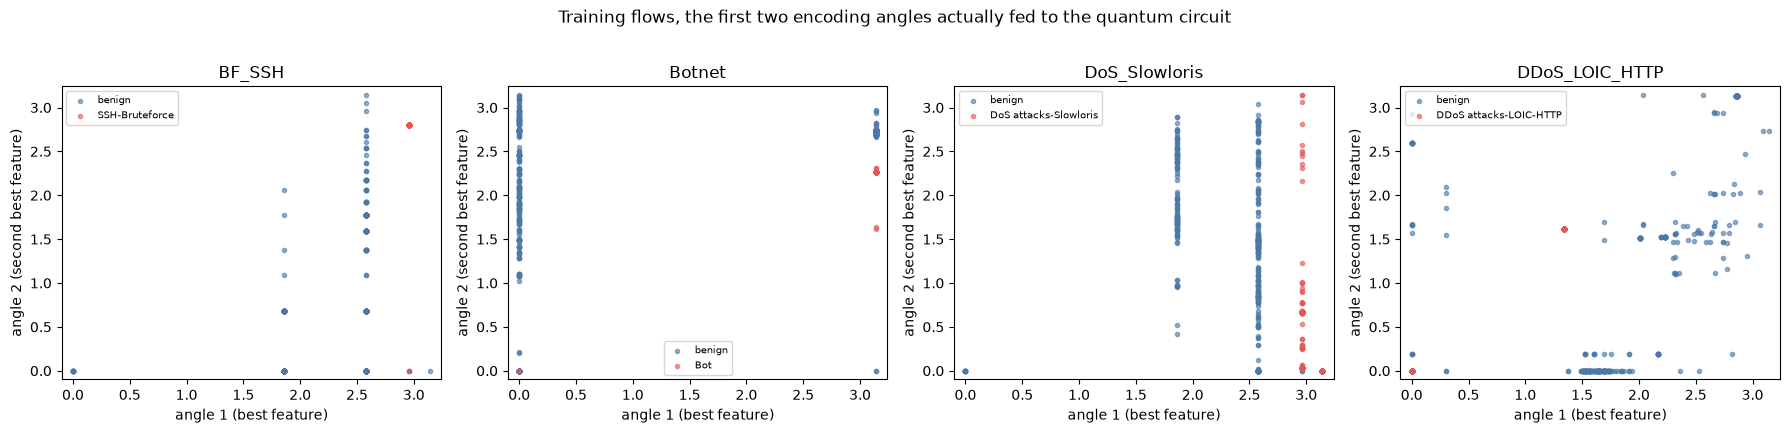

angle-1 / angle-2 features per attack: {'BF_SSH': ['Fwd Seg Size Min', 'Fwd Act Data Packets'], 'Botnet': ['RST Flag Count', 'Packet Length Std'], 'DoS_Slowloris': ['Fwd Seg Size Min', 'Flow Bytes/s'], 'DDoS_LOIC_HTTP': ['Fwd Packet Length Max', 'Init Bwd Win Bytes']}


In [9]:
# (b) the same PCA coordinates scaled to [0, pi] (MinMax fitted on the training coordinates)
MMP = {name: MinMaxScaler((0, np.pi)).fit(PCAS[name].transform(d[name]["Ztr"])) for name in ATTACK_NAMES}
scatter4(lambda n: (*np.clip(MMP[n].transform(PCAS[n].transform(d[n]["Ztr"])), 0, np.pi).T, d[n]["ytr"]),
         "Training flows, the PCA coordinates scaled to [0, pi]", "angle 1 (from PC 1)", "angle 2 (from PC 2)", lim=(-0.1, np.pi + 0.1))
# (c) the first two actual rotation angles of the model (two best XGBoost features after scaling to [0, pi])
scatter4(lambda n: (d[n]["Atr"][:, 0], d[n]["Atr"][:, 1], d[n]["ytr"]),
         "Training flows, the first two encoding angles actually fed to the quantum circuit", "angle 1 (best feature)", "angle 2 (second best feature)", lim=(-0.1, np.pi + 0.1))
print("angle-1 / angle-2 features per attack:", {n: TOP[n][:2] for n in ATTACK_NAMES})

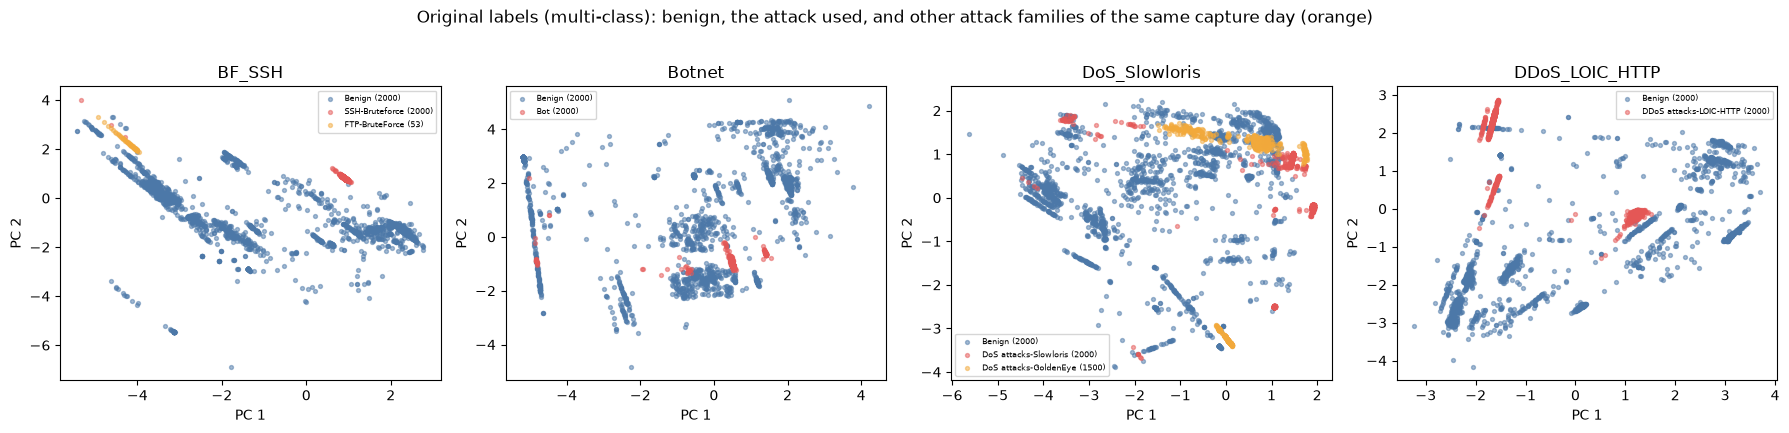

In [10]:
# (d) multi-class view: keep the other attack families that share the capture day (not used for training); PCA fitted on the selection pool
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
palette = {"Benign": "#4c78a8"}
for ax, name in zip(axes, ATTACK_NAMES):
    sc = StandardScaler().fit(slog(SEL[name][TOP[name]].values))
    pca = PCA(n_components=2, random_state=SEED).fit(sc.transform(slog(SEL[name][TOP[name]].values)))
    parts = [(SEL[name]["Label"].values, SEL[name][TOP[name]].values)]
    if len(OTHERS[name]):
        parts.append((OTHERS[name]["Label"].values, OTHERS[name][TOP[name]].values))
    labs = np.concatenate([p[0] for p in parts]); Xall = np.vstack([p[1] for p in parts])
    P = pca.transform(sc.transform(slog(Xall)))
    for lab in pd.unique(labs):
        col = "#4c78a8" if lab == "Benign" else ("#e45756" if lab == ATTACKS[name][1] else "#f2a93b")
        ax.scatter(P[labs == lab, 0], P[labs == lab, 1], s=8, alpha=0.5, c=col, label=f"{lab} ({(labs == lab).sum()})")
    ax.set_title(name); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=6)
plt.suptitle("Original labels (multi-class): benign, the attack used, and other attack families of the same capture day (orange)", y=1.02)
plt.tight_layout(); plt.show()

## 3. The quantum kernel: ZZ feature map and the fidelity (overlap) kernel

Each flow is encoded into **eight qubits** (one per selected feature) with Qiskit's `zz_feature_map` (Hadamards, single-qubit
phase rotations by 2x and two-qubit ZZ phases by 2(pi - x_i)(pi - x_j) between neighbouring qubits, repeated twice). The kernel
of two flows is the squared overlap of their states. On hardware this is the compute-uncompute circuit $U(x_1)U^\dagger(x_2)$
followed by a measurement, the probability of reading all zeros being the kernel value (Fig. 1a of the paper; the swap test of
Fig. 1b gives the same quantity with an extra ancilla). The bandwidth $b$ multiplies every angle before encoding
(`# CHOICE:`; the paper does not state its scaling).

Four implementations of the same kernel are used and checked against each other:

1. `FidelityStatevectorKernel` + `QSVC` from qiskit-machine-learning (the reference implementation);
2. the same kernel computed by hand from `Statevector` objects;
3. a vectorised NumPy simulation of the ZZ feature map, used for the many repeated experiments (every layer of the ZZ map is a
   diagonal phase, so it costs one 256 x 256 Hadamard product per repetition);
4. the actual compute-uncompute circuit, transpiled to the IBM Eagle native gates and run on Aer without noise (this is the circuit
   that is later run with noise).

In [11]:
# ---- vectorised exact simulation of zz_feature_map(8, reps, linear): every layer is H^(x)8 followed by a diagonal phase
_idx = np.arange(2 ** N_QUBITS)
ZBITS = ((_idx[:, None] >> np.arange(N_QUBITS)) & 1)                  # bit i of the basis index = qubit i (Qiskit little endian)
HN = np.array([[(-1) ** bin(a & b).count("1") for b in _idx] for a in _idx]) / np.sqrt(2 ** N_QUBITS)

def zz_states(X, reps=FM_REPS):
    X = np.atleast_2d(X)
    ph = 2 * X @ ZBITS.T.astype(float)                                  # P(2 x_i) on every qubit
    for i in range(N_QUBITS - 1):                                       # linear entanglement: CX P(2 (pi-x_i)(pi-x_j)) CX
        ph += (2 * (np.pi - X[:, i]) * (np.pi - X[:, i + 1]))[:, None] * (ZBITS[:, i] ^ ZBITS[:, i + 1]).astype(float)[None, :]
    D = np.exp(1j * ph)
    psi = np.zeros((X.shape[0], 2 ** N_QUBITS), complex); psi[:, 0] = 1
    for _ in range(reps):
        psi = (psi @ HN) * D
    return psi

def qkernel(A, B, bw):
    # fidelity kernel |<phi(a)|phi(b)>|^2 of two sets of angle vectors (angles multiplied by the bandwidth bw)
    Sa, Sb = zz_states(np.asarray(A) * bw), zz_states(np.asarray(B) * bw)
    return np.abs(Sa.conj() @ Sb.T) ** 2

fm = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT)       # the Qiskit feature map U(x)

# ---- check 1: the NumPy states equal Qiskit's Statevector (up to a global phase)
Xchk = np.random.default_rng(SEED).random((6, N_QUBITS)) * np.pi
S_np = zz_states(Xchk)
S_qk = np.array([Statevector(fm.assign_parameters(x)).data for x in Xchk])
print("state overlaps |<qiskit|numpy>| (all must be 1):", np.round(np.abs(np.einsum("ij,ij->i", S_qk.conj(), S_np)), 12))
assert np.allclose(np.abs(np.einsum("ij,ij->i", S_qk.conj(), S_np)), 1.0)

state overlaps |<qiskit|numpy>| (all must be 1): [1. 1. 1. 1. 1. 1.]


In [12]:
# ---- the compute-uncompute circuit U(x) U^dagger(y) with separate parameters, transpiled to the IBM Eagle native gates
from qiskit.circuit.library import zz_feature_map as _zz
fx = _zz(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT, parameter_prefix="x")
fy = _zz(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT, parameter_prefix="y")
fid_circuit = fx.compose(fy.inverse())                       # U(x) U^dagger(y); P(all zeros) = kernel value
fid_measured = fid_circuit.copy(); fid_measured.measure_all()

import qiskit_ibm_runtime.fake_provider as fp
backend = getattr(fp, HW_BACKEND)()
noise_model = NoiseModel.from_backend(backend)
tc = transpile(fid_circuit, backend, optimization_level=3, seed_transpiler=SEED)            # layout chosen on good qubits
PHYS = tc.layout.final_index_layout(filter_ancillas=True)
tc.append(SaveProbabilities(N_QUBITS), PHYS)                                                # exact distribution over the 8 used qubits
PARAMS = list(fx.parameters) + list(fy.parameters)
print("backend:", backend.name, "| qubits on device:", backend.num_qubits, "| physical qubits used:", PHYS)

def bind(Arow, Brow, bw):
    return tc.assign_parameters(dict(zip(PARAMS, np.concatenate([np.asarray(Arow) * bw, np.asarray(Brow) * bw]))))

# ---- check 4: ideal (noiseless) Aer run of the transpiled circuit equals the NumPy kernel
ideal = AerSimulator(method="density_matrix")
rr = np.random.default_rng(SEED)
Ax, Bx = rr.random((4, N_QUBITS)) * np.pi, rr.random((4, N_QUBITS)) * np.pi
res = ideal.run([bind(a, b, 1.0) for a, b in zip(Ax, Bx)]).result()
p_aer = np.array([res.data(i)["probabilities"][0] for i in range(4)])
p_np = np.array([qkernel(Ax[i:i+1], Bx[i:i+1], 1.0)[0, 0] for i in range(4)])
print("kernel values, transpiled circuit on ideal Aer:", np.round(p_aer, 6))
print("kernel values, NumPy statevector              :", np.round(p_np, 6))
assert np.allclose(p_aer, p_np, atol=1e-9)

backend: fake_sherbrooke | qubits on device: 127 | physical qubits used: [118, 119, 120, 121, 122, 123, 124, 125]


kernel values, transpiled circuit on ideal Aer: [0.000195 0.017526 0.002082 0.002307]
kernel values, NumPy statevector              : [0.000195 0.017526 0.002082 0.002307]


## Quantum Circuit Architecture

The quantum model has no trainable circuit parameters: the circuit is a fixed **feature map** (data encoding) and the training
happens classically (SVM on the kernel matrix), so the number of trainable quantum parameters is zero; the 8 data-dependent
rotation angles per circuit are inputs. Three views of what is executed:

1. the feature map $U(x)$ (encoding and entanglement) that defines every state;
2. the compute-uncompute circuit $U(x)U^\dagger(y)$ with the all-zero measurement (the kernel circuit run on the emulated device);
3. the same circuit transpiled to the IBM Eagle native gates (`ecr`, `rz`, `sx`, `x`) on the best 8 connected qubits of the 127,
   which is the circuit that receives noise.

Assumptions where the paper is silent: ZZ feature map, 2 repetitions, linear entanglement, overlap (not swap) test, 8 qubits.

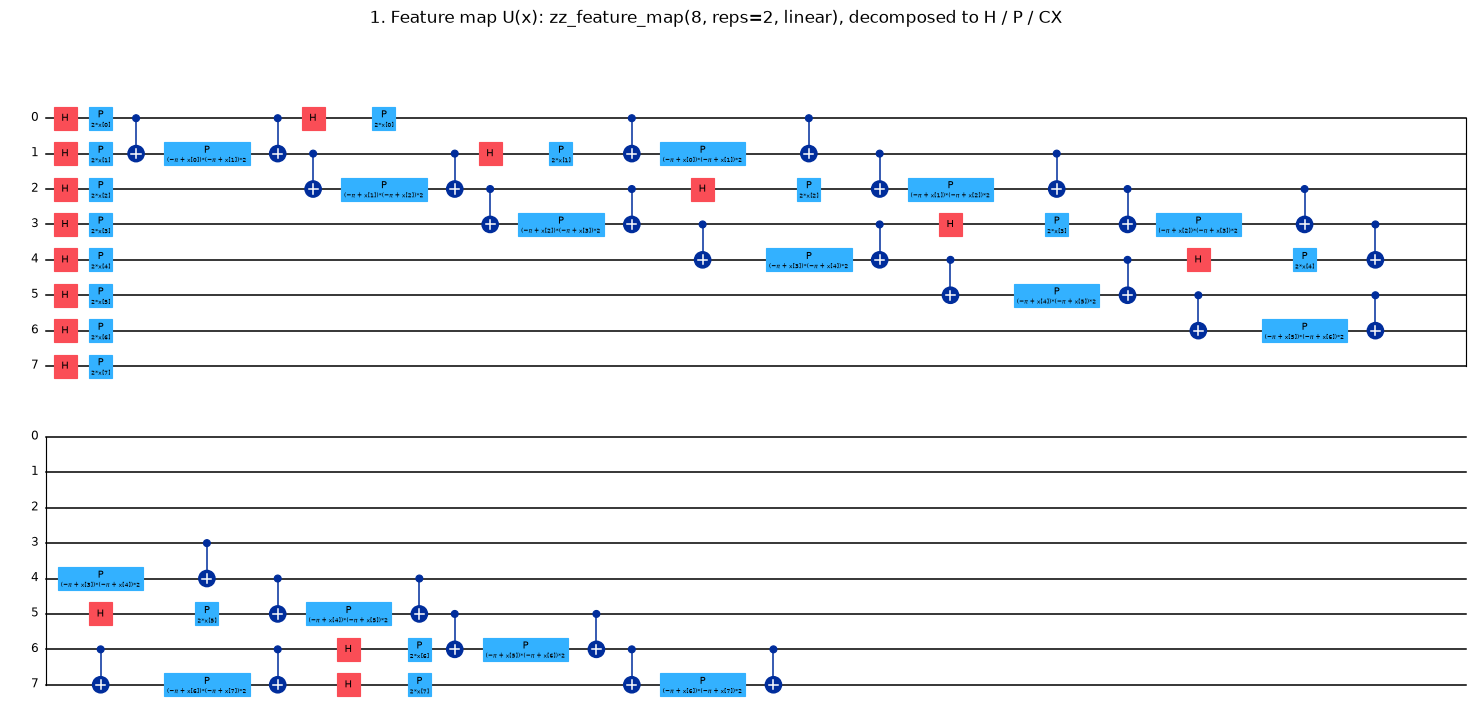

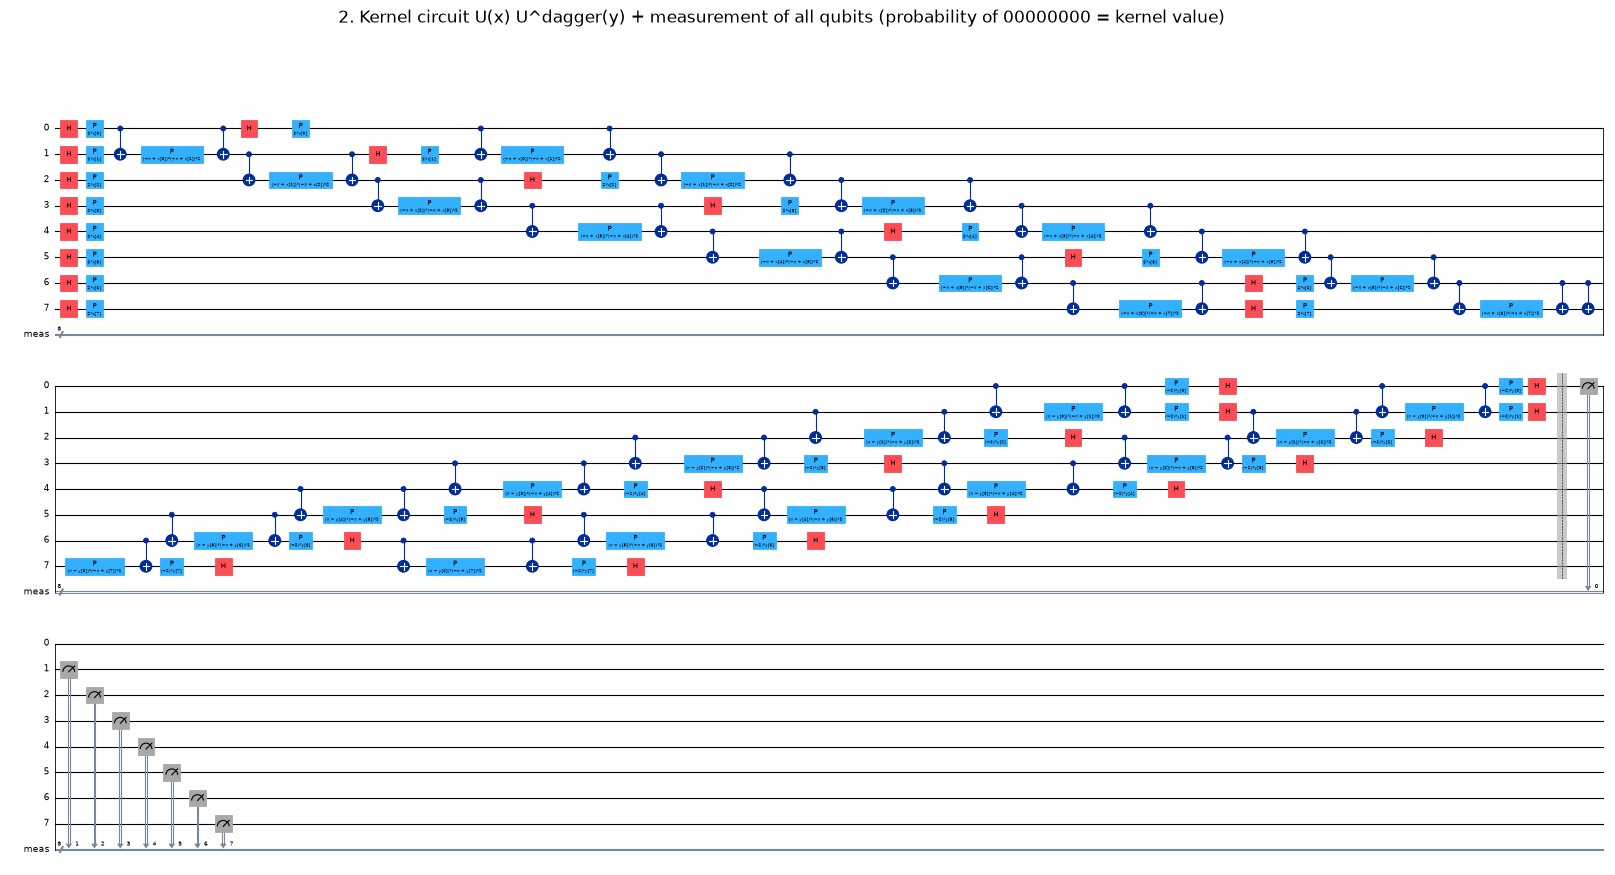

,qubits used,depth,two-qubit gates,total gates,trainable quantum parameters,data angles (inputs)
circuit,,,,,,
"U(x) (feature map, decomposed)",8,31,28,74,0,8
U(x)U^dagger(y) + measure (decomposed),8,63,56,148,0,16
transpiled for fake_sherbrooke,8,184,54,476,0,16


qubit count: 8 | depth of U(x): 31 | depth of the kernel circuit: 63 | transpiled depth: 184 | trainable parameters: 0 (fixed feature map; the SVM is trained classically)


In [13]:
def flatten(qc):
    basis = {"u", "p", "u1", "cx", "h", "rz", "sx", "x", "ecr", "measure", "barrier"}
    while any(i.operation.name not in basis for i in qc.data):
        qc = qc.decompose()
    return qc

fm_flat = flatten(fm)
fig = fm_flat.draw("mpl", fold=40, scale=0.55)
fig.suptitle("1. Feature map U(x): zz_feature_map(8, reps=2, linear), decomposed to H / P / CX"); display(fig); plt.close(fig)
fid_flat = flatten(fid_measured)
fig = fid_flat.draw("mpl", fold=60, scale=0.4)
fig.suptitle("2. Kernel circuit U(x) U^dagger(y) + measurement of all qubits (probability of 00000000 = kernel value)"); display(fig); plt.close(fig)

tc_plain = transpile(fid_circuit, backend, optimization_level=3, seed_transpiler=SEED)
rows = []
for label, qc, ntrain in (("U(x) (feature map, decomposed)", fm_flat, 0), ("U(x)U^dagger(y) + measure (decomposed)", fid_flat, 0), ("transpiled for " + backend.name, tc_plain, 0)):
    ops = dict(qc.count_ops())
    used = len({qc.find_bit(q).index for inst in qc.data for q in inst.qubits})
    rows.append({"circuit": label, "qubits used": used, "depth": qc.depth(), "two-qubit gates": ops.get("cx", 0) + ops.get("ecr", 0),
                 "total gates": sum(v for k, v in ops.items() if k not in ("barrier", "measure")), "trainable quantum parameters": 0,
                 "data angles (inputs)": qc.num_parameters})
display(pd.DataFrame(rows).set_index("circuit"))
print("qubit count:", N_QUBITS, "| depth of U(x):", fm_flat.depth(), "| depth of the kernel circuit:", fid_flat.depth(), "| transpiled depth:", tc_plain.depth(),
      "| trainable parameters: 0 (fixed feature map; the SVM is trained classically)")

In [14]:
# Reference implementation 1 and hand-computed kernel 2 (small sample), compared with the NumPy kernel 3 -> must agree
dchk = draw_sample("BF_SSH", N_SMALL, 0)
BW_CHK = 0.5
qk_ref = FidelityStatevectorKernel(feature_map=fm)                       # angles = bandwidth * data
K_ref = qk_ref.evaluate(x_vec=BW_CHK * dchk["Atr"])
K_np = qkernel(dchk["Atr"], dchk["Atr"], BW_CHK)
sv = [Statevector(fm.assign_parameters(BW_CHK * a)) for a in dchk["Atr"]]
K_hand = np.array([[abs(a.inner(b)) ** 2 for b in sv] for a in sv])
print("FidelityStatevectorKernel vs NumPy kernel  :", np.allclose(K_ref, K_np, atol=1e-9))
print("hand-made Statevector overlaps vs NumPy    :", np.allclose(K_hand, K_np, atol=1e-9))
assert np.allclose(K_ref, K_np, atol=1e-9) and np.allclose(K_hand, K_np, atol=1e-9)
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fm), C=SVM_C)
Xq_tr, Xq_te = BW_CHK * dchk["Atr"], BW_CHK * dchk["Ate"]
t0 = time.time(); qsvc.fit(Xq_tr, dchk["ytr"]); p_qsvc = qsvc.predict(Xq_te); t_q = time.time() - t0
svc_pre = SVC(kernel="precomputed", C=SVM_C).fit(K_np, dchk["ytr"]); p_pre = svc_pre.predict(qkernel(dchk["Ate"], dchk["Atr"], BW_CHK))
print(f"QSVC predictions == SVC(precomputed) predictions on the NumPy kernel: {np.array_equal(p_qsvc, p_pre)}  (QSVC fit+predict {t_q:.1f} s)")
print("test accuracy of this BF_SSH draw (n = 60, bandwidth 0.5):", accuracy_score(dchk["yte"], p_qsvc))

FidelityStatevectorKernel vs NumPy kernel  : True
hand-made Statevector overlaps vs NumPy    : True


QSVC predictions == SVC(precomputed) predictions on the NumPy kernel: True  (QSVC fit+predict 2.2 s)
test accuracy of this BF_SSH draw (n = 60, bandwidth 0.5): 1.0


## 4. Training and evaluating all models

For every attack and every random draw the notebook trains

* **QK-SVC (noiseless)**: SVM on the exact fidelity kernel. The bandwidth is chosen from `BW_GRID` by 3-fold cross-validation
  inside the training split only; `C = 1` as in scikit-learn's default.
* **SVC-RBF**: scikit-learn `SVC(kernel="rbf")` with all defaults (`C = 1`, `gamma = "scale"`), the paper's classical benchmark,
  on the same eight angle-scaled features.
* **RandomForest** (200 trees) and **SVC-linear**, extra baselines on the same eight features.

Metrics: accuracy (the paper's metric), and precision / recall / F1 with the attack as the positive class. Wall-clock time
covers kernel computation (including the bandwidth search), fitting and predicting.

In [15]:
def tune_bandwidth(Atr, ytr):
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    scores = []
    for bw in BW_GRID:
        K = qkernel(Atr, Atr, bw); acc = []
        for tr, va in skf.split(Atr, ytr):
            acc.append(SVC(kernel="precomputed", C=SVM_C).fit(K[np.ix_(tr, tr)], ytr[tr]).score(K[np.ix_(va, tr)], ytr[va]))
        scores.append(np.mean(acc))
    return BW_GRID[int(np.argmax(scores))], scores            # ties -> the smaller bandwidth

def metrics(y, p):
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, zero_division=0), rec=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0))

def run_draw(name, n, draw):
    d = draw_sample(name, n, draw)
    Atr, Ate, ytr, yte = d["Atr"], d["Ate"], d["ytr"], d["yte"]
    out, preds = [], {}
    t0 = time.time()
    bw, cv = tune_bandwidth(Atr, ytr)
    svc = SVC(kernel="precomputed", C=SVM_C).fit(qkernel(Atr, Atr, bw), ytr)
    p = svc.predict(qkernel(Ate, Atr, bw)); preds["QK-SVC (noiseless)"] = p
    out.append(dict(model="QK-SVC (noiseless)", time=time.time() - t0, bandwidth=bw, **metrics(yte, p)))
    for label, mdl in (("SVC-RBF", SVC(kernel="rbf")), ("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2)),
                       ("SVC-linear", SVC(kernel="linear"))):
        t0 = time.time(); mdl.fit(Atr, ytr); p = mdl.predict(Ate); preds[label] = p
        out.append(dict(model=label, time=time.time() - t0, bandwidth=np.nan, **metrics(yte, p)))
    for o in out:
        o.update(attack=name, n=n, draw=draw)
    return out, preds, d

RECORDS, PREDS, DATA0 = [], {}, {}
t_all = time.time()
for n, R in ((N_SMALL, R_SMALL), (N_LARGE, R_LARGE)):
    t0 = time.time()
    for name in ATTACK_NAMES:
        for draw in range(R):
            out, preds, d = run_draw(name, n, draw)
            RECORDS += out
            if draw == 0:
                PREDS[(name, n)] = preds; DATA0[(name, n)] = d
    print(f"n = {n}: {len(ATTACK_NAMES)} attacks x {R} draws done in {time.time()-t0:.0f} s")
REC = pd.DataFrame(RECORDS)
print(f"total {time.time()-t_all:.0f} s")

n = 60: 4 attacks x 10 draws done in 154 s


n = 1000: 4 attacks x 10 draws done in 314 s
total 467 s


In [16]:
summ = (REC.groupby(["n", "attack", "model"]).agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), prec=("prec", "mean"), rec=("rec", "mean"),
                                                   f1=("f1", "mean"), time_s=("time", "mean")).round(3))
for n in (N_SMALL, N_LARGE):
    print(f"==== n = {n} ({'test points per draw: ' + str(int(n*TEST_SIZE))}) ====")
    display(summ.loc[n].unstack("model")[["acc_mean", "acc_std"]])

==== n = 60 (test points per draw: 12) ====


acc_mean                                            acc_std                                
model          QK-SVC (noiseless) RandomForest SVC-RBF SVC-linear QK-SVC (noiseless) RandomForest SVC-RBF SVC-linear
attack                                                                                                              
BF_SSH                      1.000        1.000   1.000      1.000              0.000        0.000   0.000      0.000
Botnet                      0.983        0.942   0.983      0.933              0.035        0.069   0.035      0.077
DDoS_LOIC_HTTP              0.983        0.950   0.925      0.950              0.035        0.058   0.073      0.058
DoS_Slowloris               0.975        0.967   0.933      0.975              0.040        0.058   0.095      0.040

==== n = 1000 (test points per draw: 200) ====


acc_mean                                            acc_std                                
model          QK-SVC (noiseless) RandomForest SVC-RBF SVC-linear QK-SVC (noiseless) RandomForest SVC-RBF SVC-linear
attack                                                                                                              
BF_SSH                      0.998        1.000   0.997      0.998              0.003        0.002   0.003      0.003
Botnet                      0.991        0.996   0.991      0.991              0.005        0.002   0.006      0.005
DDoS_LOIC_HTTP              0.994        0.992   0.988      0.970              0.006        0.009   0.008      0.014
DoS_Slowloris               0.993        0.998   0.978      0.997              0.006        0.003   0.009      0.003

In [17]:
# precision / recall / F1 (attack = positive class) averaged over draws, and the mean over the four attacks
for n in (N_SMALL, N_LARGE):
    t = REC[REC.n == n].groupby("model")[["acc", "prec", "rec", "f1", "time"]].mean().round(3)
    t["acc_std_over_draws_and_attacks"] = REC[REC.n == n].groupby("model")["acc"].std().round(3)
    print(f"n = {n}: mean over four attacks and {R_SMALL if n == N_SMALL else R_LARGE} draws"); display(t)
print("bandwidths selected by cross-validation (counts):")
display(REC[REC.model == "QK-SVC (noiseless)"].groupby(["n", "bandwidth"]).size().unstack(fill_value=0))

n = 60: mean over four attacks and 10 draws


,acc,prec,rec,f1,time,acc_std_over_draws_and_attacks
model,,,,,,
QK-SVC (noiseless),0.985,1.000,0.971,0.984,1.020,0.032
RandomForest,0.965,0.964,0.971,0.965,2.500,0.056
SVC-RBF,0.960,0.954,0.979,0.963,0.011,0.068
SVC-linear,0.965,0.955,0.983,0.967,0.012,0.056


n = 1000: mean over four attacks and 10 draws


,acc,prec,rec,f1,time,acc_std_over_draws_and_attacks
model,,,,,,
QK-SVC (noiseless),0.994,0.998,0.990,0.994,4.754,0.006
RandomForest,0.996,0.997,0.996,0.996,2.657,0.005
SVC-RBF,0.989,0.992,0.986,0.989,0.038,0.010
SVC-linear,0.989,0.986,0.992,0.989,0.031,0.014


bandwidths selected by cross-validation (counts):


bandwidth,0.05,0.10,0.25,0.50,1.00
n,,,,,
60,16,10,10,2,2
1000,14,6,11,7,2


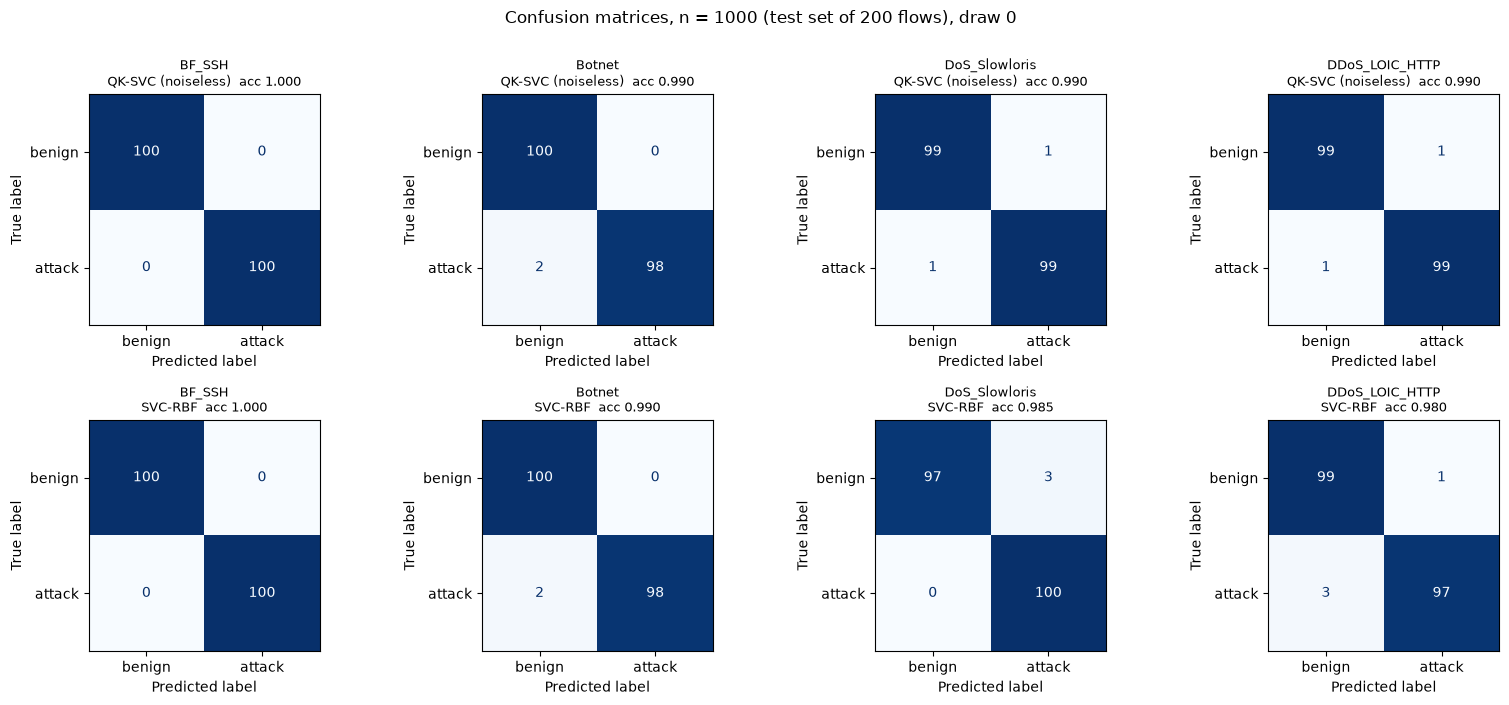

In [18]:
# confusion matrices of draw 0 (attack = positive class): quantum kernel versus RBF kernel, n = 1,000
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, name in enumerate(ATTACK_NAMES):
    for i, label in enumerate(("QK-SVC (noiseless)", "SVC-RBF")):
        yte = DATA0[(name, N_LARGE)]["yte"]; p = PREDS[(name, N_LARGE)][label]
        ConfusionMatrixDisplay(confusion_matrix(yte, p, labels=[0, 1]), display_labels=["benign", "attack"]).plot(ax=axes[i, j], colorbar=False, cmap="Blues")
        axes[i, j].set_title(f"{name}\n{label}  acc {accuracy_score(yte, p):.3f}", fontsize=9)
plt.suptitle(f"Confusion matrices, n = {N_LARGE} (test set of {int(N_LARGE*TEST_SIZE)} flows), draw 0", y=1.0)
plt.tight_layout(); plt.show()

## 5. The "hardware" experiment: an emulated 127-qubit IBM Eagle device

The paper ran the n = 60 kernels ten times on the 127-qubit `ibm_rensselaer`. We have no access to it, so this section runs the
**same kernel circuits** (Fig. 1a, transpiled to the Eagle native gates on the best eight connected qubits) through Aer's
density-matrix simulator with the full noise model of `FakeSherbrooke` (gate errors, thermal relaxation, readout errors from a
calibration snapshot). It is an emulation: it contains no drift, crosstalk or compilation difference of the real machine, so it
can neither confirm nor refute the paper's hardware number, only show what a device of that class would roughly do.

How the "ten iterations" are emulated without ten times the compute: for every kernel entry the exact probability $P_0$ of
reading all zeros (readout errors included) is obtained once from the density matrix; one hardware iteration then draws the
number of all-zero shots from a binomial distribution with `HW_SHOTS` shots, which is exactly the distribution of a real finite-shot
measurement of the same noisy state. The ten iterations therefore differ only by shot noise, the paper's iterations also by drift.
The circuit bandwidth is the one chosen by the noiseless cross-validation for that draw. Cost: about 0.5 s per circuit on a shared
laptop CPU (an n-flow kernel needs about 0.8 n^2 circuits, i.e. about 1,700 circuits for n = 60).

In [19]:
# readout-error confusion matrices of the used physical qubits (taken from the noise model), to convert the exact
# probabilities over the 8 measured qubits into P(read 00000000)
_ro = {e["gate_qubits"][0][0]: np.array(e["probabilities"]) for e in noise_model.to_dict()["errors"] if e["type"] == "roerror"}
_wbits = np.arange(2 ** N_QUBITS)
READ0 = np.ones(2 ** N_QUBITS)
for k, q in enumerate(PHYS):
    READ0 = READ0 * _ro[q][(_wbits >> k) & 1, 0]          # P(measure 0 | prepared bit)
noisy_sim = AerSimulator(noise_model=noise_model, method="density_matrix", max_parallel_experiments=4, max_parallel_threads=4)

def noisy_P0(pairs_A, pairs_B, bw, chunk=48, label=""):
    # exact noisy P(all zeros) of the kernel circuit for every (a_i, b_i) pair, with the emulated device's readout error
    out, t0 = [], time.time()
    for s in range(0, len(pairs_A), chunk):
        cs = [bind(a, b, bw) for a, b in zip(pairs_A[s:s + chunk], pairs_B[s:s + chunk])]
        res = noisy_sim.run(cs).result()
        out += [float((np.asarray(res.data(i)["probabilities"]) * READ0).sum()) for i in range(len(cs))]
        if (s // chunk) % 5 == 4 or s + chunk >= len(pairs_A):
            print(f"  {label}: {min(s + chunk, len(pairs_A))}/{len(pairs_A)} circuits, {time.time() - t0:.0f} s", flush=True)
    return np.array(out)

# sanity check of the analytic readout step against Aer's own shot-based counts (100,000 shots, 2 circuits)
_fm2 = transpile(fid_measured, backend, optimization_level=3, seed_transpiler=SEED)
_cm = [_fm2.assign_parameters(dict(zip(PARAMS, np.concatenate([a, b])))) for a, b in zip(Ax[:2], Bx[:2])]
_counts = noisy_sim.run(_cm, shots=100000).result()
_p_counts = np.array([_counts.get_counts(i).get("0" * N_QUBITS, 0) / 1e5 for i in range(2)])
_p_exact = noisy_P0(list(Ax[:2]), list(Bx[:2]), 1.0, label="check")
print("P(read all zeros): Aer counts", np.round(_p_counts, 5), "| exact density matrix + readout", np.round(_p_exact, 5))
assert np.all(np.abs(_p_counts - _p_exact) < 6 * np.sqrt(_p_exact / 1e5) + 1e-4)

  check: 2/2 circuits, 9 s


P(read all zeros): Aer counts [0.00201 0.01375] | exact density matrix + readout [0.00185 0.0138 ]


In [20]:
HW_RESULTS = {}
t_hw = time.time()
for name in HW_ATTACKS:
    d0 = draw_sample(name, HW_N, 0)
    Atr, Ate, ytr, yte = d0["Atr"], d0["Ate"], d0["ytr"], d0["yte"]
    bw, _ = tune_bandwidth(Atr, ytr)
    ntr, nte = len(Atr), len(Ate)
    iu = [(i, j) for i in range(ntr) for j in range(i, ntr)]                           # symmetric: upper triangle incl. diagonal
    P_tr_pairs = noisy_P0([Atr[i] for i, j in iu], [Atr[j] for i, j in iu], bw, label=f"{name} train kernel")
    te = [(i, j) for i in range(nte) for j in range(ntr)]
    P_te_pairs = noisy_P0([Ate[i] for i, j in te], [Atr[j] for i, j in te], bw, label=f"{name} test kernel")
    P_tr = np.zeros((ntr, ntr)); P_tr[np.triu_indices(ntr)] = P_tr_pairs; P_tr = P_tr + P_tr.T - np.diag(np.diag(P_tr))
    P_te = P_te_pairs.reshape(nte, ntr)
    # noiseless reference on the same draw and bandwidth
    K_tr, K_te = qkernel(Atr, Atr, bw), qkernel(Ate, Atr, bw)
    acc_ideal = SVC(kernel="precomputed", C=SVM_C).fit(K_tr, ytr).score(K_te, yte)
    acc_noisy_exact = SVC(kernel="precomputed", C=SVM_C).fit(P_tr, ytr).score(P_te, yte)       # infinite shots on the noisy device
    # ten finite-shot iterations
    rs = np.random.default_rng(SEED)
    accs = []
    for t in range(HW_T):
        Ktr_s = np.zeros((ntr, ntr)); Ktr_s[np.triu_indices(ntr)] = rs.binomial(HW_SHOTS, P_tr[np.triu_indices(ntr)]) / HW_SHOTS
        Ktr_s = Ktr_s + Ktr_s.T - np.diag(np.diag(Ktr_s))
        Kte_s = rs.binomial(HW_SHOTS, P_te) / HW_SHOTS
        accs.append(SVC(kernel="precomputed", C=SVM_C).fit(Ktr_s, ytr).score(Kte_s, yte))
    HW_RESULTS[name] = dict(bw=bw, n=HW_N, n_test=nte, acc_ideal=acc_ideal, acc_noisy_exact=acc_noisy_exact, acc_mean=np.mean(accs), acc_std=np.std(accs),
                            accs=accs, mean_P0_offdiag=float(P_tr[np.triu_indices(ntr, 1)].mean()), mean_K_offdiag=float(K_tr[np.triu_indices(ntr, 1)].mean()),
                            diag_P0=float(np.diag(P_tr).mean()))
print(f"emulated device: {time.time() - t_hw:.0f} s")
hw = pd.DataFrame(HW_RESULTS).T[["n", "n_test", "bw", "acc_ideal", "acc_noisy_exact", "acc_mean", "acc_std", "diag_P0", "mean_K_offdiag", "mean_P0_offdiag"]]
display(hw.astype(float).round(3))
print("diag_P0 is the measured K(x, x) (ideal value 1): the noise floor of the device. mean_K_offdiag / mean_P0_offdiag: average ideal vs noisy kernel value of different flows.")

  BF_SSH train kernel: 240/1176 circuits, 158 s


  BF_SSH train kernel: 480/1176 circuits, 317 s


  BF_SSH train kernel: 720/1176 circuits, 458 s


  BF_SSH train kernel: 960/1176 circuits, 610 s


  BF_SSH train kernel: 1176/1176 circuits, 733 s


...

  DDoS_LOIC_HTTP test kernel: 480/576 circuits, 206 s


  DDoS_LOIC_HTTP test kernel: 576/576 circuits, 270 s


emulated device: 3247 s


,n,n_test,bw,acc_ideal,acc_noisy_exact,acc_mean,acc_std,diag_P0,mean_K_offdiag,mean_P0_offdiag
BF_SSH,60.0,12.0,0.05,1.000,1.000,1.000,0.0,0.563,0.565,0.329
Botnet,60.0,12.0,0.05,1.000,1.000,1.000,0.0,0.582,0.608,0.367
DoS_Slowloris,60.0,12.0,0.50,0.917,0.917,0.917,0.0,0.534,0.089,0.051
DDoS_LOIC_HTTP,60.0,12.0,0.25,1.000,1.000,1.000,0.0,0.525,0.120,0.066


diag_P0 is the measured K(x, x) (ideal value 1): the noise floor of the device. mean_K_offdiag / mean_P0_offdiag: average ideal vs noisy kernel value of different flows.


In [21]:
# Optional: the same kernel on real IBM hardware (skipped unless IBM_TOKEN is set; NOT run for the committed notebook).
if IBM_TOKEN:
    try:
        from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
        real = service.least_busy(operational=True, simulator=False, min_num_qubits=N_QUBITS)
        name = HW_ATTACKS[0]; d0 = draw_sample(name, HW_N, 0); bw, _ = tune_bandwidth(d0["Atr"], d0["ytr"])
        tcm = transpile(fid_measured, real, optimization_level=3, seed_transpiler=SEED)
        Atr, Ate = d0["Atr"], d0["Ate"]
        pubs = [tcm.assign_parameters(dict(zip(PARAMS, np.concatenate([a * bw, b * bw])))) for a in np.vstack([Atr, Ate]) for b in Atr]
        job = SamplerV2(mode=real).run(pubs, shots=HW_SHOTS)                      # untested here: needs a real token and queue time
        print("submitted job", job.job_id(), "to", real.name, "- fetch the counts with job.result() and build the kernel as above")
    except Exception as e:
        print("real-hardware run failed:", type(e).__name__, str(e)[:200])
else:
    print("IBM_TOKEN is empty: real-hardware run skipped (the emulated device above stands in for ibm_rensselaer).")

IBM_TOKEN is empty: real-hardware run skipped (the emulated device above stands in for ibm_rensselaer).


## 6. The paper's Figures 2 and 3, redrawn

Solid lines are this notebook (mean over draws, error bars = standard deviation over draws; the emulated device shows the mean and
standard deviation over its ten shot-noise iterations on draw 0). Hollow markers are the values read off the paper's plots.

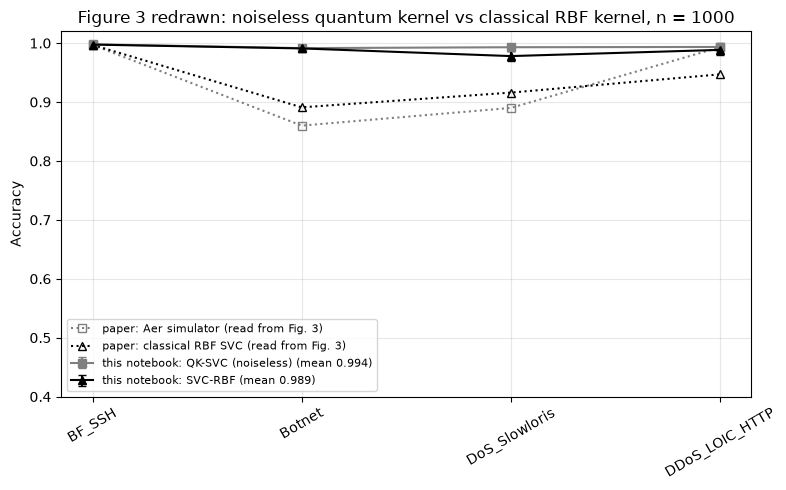

In [22]:
PAPER = {
    "fig3_aer": dict(BF_SSH=0.997, Botnet=0.860, DoS_Slowloris=0.890, DDoS_LOIC_HTTP=0.993),
    "fig3_svc": dict(BF_SSH=0.997, Botnet=0.891, DoS_Slowloris=0.916, DDoS_LOIC_HTTP=0.947),
    "fig2_aer": dict(BF_SSH=1.000, Botnet=0.889, DoS_Slowloris=0.944, DDoS_LOIC_HTTP=1.000),
    "fig2_svc": dict(BF_SSH=0.975, Botnet=0.929, DoS_Slowloris=0.857, DDoS_LOIC_HTTP=0.953),
    "fig2_hw":  dict(BF_SSH=0.929, Botnet=0.761, DoS_Slowloris=0.867, DDoS_LOIC_HTTP=0.800),
    "fig2_hw_sigma": dict(BF_SSH=0.07, Botnet=0.045, DoS_Slowloris=0.03, DDoS_LOIC_HTTP=0.10),
    "hw_mean_abstract": 0.85, "fig3_aer_mean": 0.935, "fig3_svc_mean": 0.937,
}
PLAB = {"QK-SVC (noiseless)": "Aer simulator", "SVC-RBF": "classical RBF SVC"}
def mean_std(n, model):
    g = REC[(REC.n == n) & (REC.model == model)].groupby("attack")["acc"].agg(["mean", "std"]).reindex(ATTACK_NAMES)
    return g["mean"].values, g["std"].fillna(0).values
x = np.arange(4)
fig, ax = plt.subplots(figsize=(8, 5))
for model, col, mk, key in (("QK-SVC (noiseless)", "tab:gray", "s", "fig3_aer"), ("SVC-RBF", "k", "^", "fig3_svc")):
    m, s = mean_std(N_LARGE, model)
    ax.errorbar(x, m, yerr=s, color=col, marker=mk, label=f"this notebook: {model} (mean {m.mean():.3f})", capsize=3)
    ax.plot(x, [PAPER[key][a] for a in ATTACK_NAMES], color=col, marker=mk, mfc="none", ls=":", label=f"paper: {PLAB[model]} (read from Fig. 3)")
ax.set_xticks(x); ax.set_xticklabels(ATTACK_NAMES, rotation=30); ax.set_ylim(0.4, 1.02); ax.set_ylabel("Accuracy"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower left")
ax.set_title(f"Figure 3 redrawn: noiseless quantum kernel vs classical RBF kernel, n = {N_LARGE}"); plt.tight_layout(); plt.show()

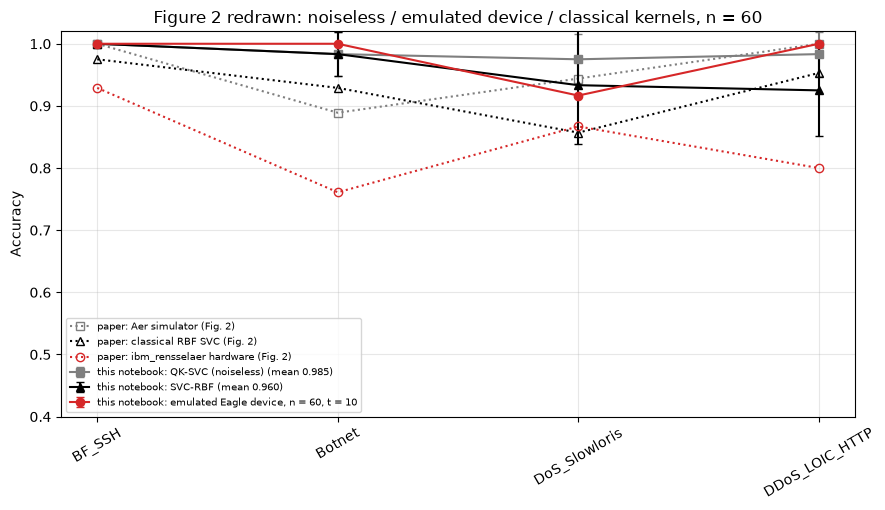

In [23]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for model, col, mk, key in (("QK-SVC (noiseless)", "tab:gray", "s", "fig2_aer"), ("SVC-RBF", "k", "^", "fig2_svc")):
    m, s = mean_std(N_SMALL, model)
    ax.errorbar(x, m, yerr=s, color=col, marker=mk, label=f"this notebook: {model} (mean {m.mean():.3f})", capsize=3)
    ax.plot(x, [PAPER[key][a] for a in ATTACK_NAMES], color=col, marker=mk, mfc="none", ls=":", label=f"paper: {PLAB[model]} (Fig. 2)")
hx = [i for i, a in enumerate(ATTACK_NAMES) if a in HW_RESULTS]
if hx:
    ax.errorbar(hx, [HW_RESULTS[ATTACK_NAMES[i]]["acc_mean"] for i in hx], yerr=[HW_RESULTS[ATTACK_NAMES[i]]["acc_std"] for i in hx], color="tab:red", marker="o",
                capsize=3, label=f"this notebook: emulated Eagle device, n = {HW_N}, t = {HW_T}")
ax.plot(x, [PAPER["fig2_hw"][a] for a in ATTACK_NAMES], color="tab:red", marker="o", mfc="none", ls=":", label="paper: ibm_rensselaer hardware (Fig. 2)")
ax.set_xticks(x); ax.set_xticklabels(ATTACK_NAMES, rotation=30); ax.set_ylim(0.4, 1.02); ax.set_ylabel("Accuracy"); ax.grid(alpha=0.3); ax.legend(fontsize=7, loc="lower left")
ax.set_title(f"Figure 2 redrawn: noiseless / emulated device / classical kernels, n = {N_SMALL}" + ("" if len(HW_ATTACKS) == 4 else f" (device emulation only for {HW_ATTACKS}, n = {HW_N})"))
plt.tight_layout(); plt.show()

## 7. Side by side with the paper

Verdict rule: "reproduced" when the notebook is within 2 accuracy points of the paper's value, otherwise "not reached" (ours lower)
or "exceeded" (ours higher), with the gap. The paper's per-attack numbers are read off the figures (about +-0.01). Statements
about the real quantum computer "cannot be checked" here; for them the emulated-device number is shown for context.

In [24]:
def verdict(ours, paper, tol=0.02):
    gap = ours - paper
    if abs(gap) <= tol: return f"reproduced (gap {gap:+.3f})"
    return (f"exceeded (gap {gap:+.3f})" if gap > 0 else f"not reached (gap {gap:+.3f})")

rows = []
def add(claim, paper, ours, kind="num"):
    rows.append({"claim": claim, "paper": paper if isinstance(paper, str) else round(paper, 3),
                 "this notebook": ours if isinstance(ours, str) else round(ours, 3),
                 "verdict": ("" if isinstance(ours, str) else verdict(ours, paper))})
m3a, _ = mean_std(N_LARGE, "QK-SVC (noiseless)"); m3s, _ = mean_std(N_LARGE, "SVC-RBF")
m2a, _ = mean_std(N_SMALL, "QK-SVC (noiseless)"); m2s, _ = mean_std(N_SMALL, "SVC-RBF")
add(f"Fig. 3 / text: noiseless quantum kernel, mean accuracy n={N_LARGE}", PAPER["fig3_aer_mean"], m3a.mean())
add(f"Fig. 3 / text: RBF kernel, mean accuracy n={N_LARGE}", PAPER["fig3_svc_mean"], m3s.mean())
gap_paper, gap_ours = PAPER["fig3_aer_mean"] - PAPER["fig3_svc_mean"], m3a.mean() - m3s.mean()
rows.append({"claim": "Quantum kernel matches RBF at n=1,000 (mean gap, simulator minus RBF)", "paper": round(gap_paper, 3), "this notebook": round(gap_ours, 3),
             "verdict": "reproduced" if abs(gap_ours) <= 0.02 else f"not reproduced (gap {gap_ours:+.3f}, tolerance 0.02)"})
for i, a in enumerate(ATTACK_NAMES):
    add(f"Fig. 3: quantum kernel, {a}, n={N_LARGE}", PAPER["fig3_aer"][a], m3a[i])
for i, a in enumerate(ATTACK_NAMES):
    add(f"Fig. 3: RBF kernel, {a}, n={N_LARGE}", PAPER["fig3_svc"][a], m3s[i])
add(f"Fig. 2: noiseless quantum kernel, mean over attacks, n={N_SMALL}", float(np.mean(list(PAPER["fig2_aer"].values()))), m2a.mean())
add(f"Fig. 2: RBF kernel, mean over attacks, n={N_SMALL}", float(np.mean(list(PAPER["fig2_svc"].values()))), m2s.mean())
for i, a in enumerate(ATTACK_NAMES):
    add(f"Fig. 2: quantum kernel, {a}, n={N_SMALL}", PAPER["fig2_aer"][a], m2a[i])
for i, a in enumerate(ATTACK_NAMES):
    add(f"Fig. 2: RBF kernel, {a}, n={N_SMALL}", PAPER["fig2_svc"][a], m2s[i])
if HW_RESULTS:
    hw_mean = float(np.mean([HW_RESULTS[a]["acc_mean"] for a in HW_RESULTS])); hw_paper = float(np.mean([PAPER["fig2_hw"][a] for a in HW_RESULTS]))
    full = len(HW_RESULTS) == 4
    rows.append({"claim": f"Hardware mean accuracy ({'all four attacks' if full else str(list(HW_RESULTS))}, n={HW_N}) vs emulated Eagle device",
                 "paper": round(PAPER["hw_mean_abstract"] if full else hw_paper, 3), "this notebook": round(hw_mean, 3),
                 "verdict": "cannot be checked on hardware; emulator gap " + f"{hw_mean - (PAPER['hw_mean_abstract'] if full else hw_paper):+.3f}"
                            + (" (emulator within 2 points)" if abs(hw_mean - (PAPER['hw_mean_abstract'] if full else hw_paper)) <= 0.02 else "")
                            + ("" if full else " (fewer attacks and fewer flows than the paper: not comparable)")})
    sd = float(np.mean([HW_RESULTS[a]["acc_std"] for a in HW_RESULTS])); sd_p = float(np.mean([PAPER["fig2_hw_sigma"][a] for a in HW_RESULTS]))
    rows.append({"claim": "Run-to-run spread of the device (std over ten iterations; paper: shaded band read off Fig. 2)", "paper": round(sd_p, 3), "this notebook": round(sd, 3),
                 "verdict": "cannot be checked (emulation has shot noise only, no drift)"})
    rows.append({"claim": "Noisy device loses accuracy against the noiseless simulator (n=60)", "paper": round(float(np.mean([PAPER['fig2_aer'][a] - PAPER['fig2_hw'][a] for a in HW_RESULTS])), 3),
                 "this notebook": round(float(np.mean([HW_RESULTS[a]['acc_ideal'] - HW_RESULTS[a]['acc_mean'] for a in HW_RESULTS])), 3),
                 "verdict": "cannot be checked on hardware (emulator drop shown, same draw)"})
rows.append({"claim": "Quantum speed-up over classical SVMs", "paper": "asserted as potential (theory)", "this notebook": "no timing advantage: kernel simulation is much slower than RBF", "verdict": "cannot be checked (simulation cannot show a speed-up)"})
CMP = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 250)
print(CMP.to_string(index=False))
print("\nverdict counts:", CMP["verdict"].str.split(" ").str[0].value_counts().to_dict())

                                                                                        claim                          paper                                                  this notebook                                                        verdict
                                Fig. 3 / text: noiseless quantum kernel, mean accuracy n=1000                          0.935                                                          0.994                                          exceeded (gap +0.059)
                                              Fig. 3 / text: RBF kernel, mean accuracy n=1000                          0.937                                                          0.989                                          exceeded (gap +0.052)
                        Quantum kernel matches RBF at n=1,000 (mean gap, simulator minus RBF)                         -0.002                                                          0.005                                                     reprodu

## 8. Reading the paper critically

* **A preview with very small samples.** At n = 60 the test set has 12 flows, so one wrong prediction moves the accuracy by 8.3
  points. Differences of a few points between the simulator, the RBF kernel and the hardware in Fig. 2 are within what a single
  random draw produces; the notebook's standard deviations over draws show how large that spread is. Fig. 2 gives no information
  about how many different samples were used, only about ten hardware iterations (probably of the same sample).
* **"Noise-resistant" is not what Fig. 2 shows.** The paper's hardware is on average about 11 accuracy points below its noiseless
  simulator (0.84 versus 0.96 by our reading of the plot); small run-to-run deviations mean the device is *consistently* degraded,
  not robust. In our emulation the measured kernel value of identical flows K(x, x) is only about 0.55 on the 184-layer transpiled
  circuit and the off-diagonal values fall to 55-60 % of their ideal size, yet the test accuracy does not change at all: the SVM
  needs the ordering of the kernel values, and the cross-validated bandwidths are small, so the damped kernel keeps its structure.
  Gate and readout noise of an Eagle-class device therefore do not by themselves explain the paper's 11-point drop; drift, a deeper
  circuit, a different encoding, very small test sets (12 flows) or the harder BCCC data may.
* **No quantum advantage is demonstrated.** At n = 1,000 the quantum kernel and the default RBF kernel are tied within a fraction
  of a point, and the RBF kernel is orders of magnitude cheaper. The claimed speed-up cites theory (inner-product estimation)
  but nothing in the experiment measures it, and kernel estimation from shots scales with the square of the sample size.
* **Hyper-parameters are missing.** Feature map, repetitions, entanglement, data scaling, bandwidth, `C`, the 8 : 2 split seed and
  the XGBoost settings are not stated, and the dataset (BCCC-CSE-CIC-IDS2018) is a re-extraction that is not freely
  mirrored. Our results use the original CICFlowMeter features, so absolute accuracies are not directly comparable.
* **Attacks that are easy for any model.** BF SSH and LOIC HTTP DDoS flows are almost linearly separable from benign flows with
  a handful of features, so a ceiling accuracy near 100 % says little about the kernel; the informative attacks are Botnet and Slowloris.
* **The dataset version matters more than the kernel.** With the CICFlowMeter features of the original CSE-CIC-IDS2018 every
  model in this notebook (quantum kernel, RBF, linear SVM, random forest) separates all four attacks at about 99 % at n = 1,000.
  The paper's lower numbers for Botnet and Slowloris (0.86-0.89 for both kernels in Fig. 3) therefore cannot be caused by the
  quantum kernel; they must come from the BCCC re-extraction, from its feature selection, or from a different benign sample.
  This is why the comparison table shows "exceeded" for those attacks even though the notebook is not better in any
  meaningful sense: the problem is easier on this feature set.
* **Feature selection before sampling.** The paper selects features on the dataset subset before drawing the 60 points; if that
  subset includes the evaluated flows, the selection leaks information. This notebook selects on a disjoint pool.
* **A classical benchmark with defaults only.** The RBF kernel is not tuned; a tuned RBF or a tree ensemble would likely
  match or beat every quantum number in the paper (compare the RandomForest rows above).

## 9. Exercises

1. **Bandwidth.** Add 2.0 and 4.0 to `BW_GRID`, and 0.02 and 0.05 as well. How does the cross-validated bandwidth change with
   n = 60 versus n = 1,000, and what happens to the average off-diagonal kernel value (kernel concentration)?
2. **Feature map.** Replace the ZZ map by `z_feature_map` (no entanglement) or `pauli_feature_map(paulis=["Z", "YY"])` in
   both `fm` and the NumPy simulator (or fall back to `FidelityStatevectorKernel`). Does the quantum kernel still match the RBF kernel?
3. **Depth versus noise.** Run the emulated device with `FM_REPS = 1` and `FM_REPS = 3`. Plot the measured K(x, x) and the
   accuracy against the number of two-qubit gates after transpilation.
4. **Shots.** Change `HW_SHOTS` to 128, 8,192 and 100,000. When does the shot noise stop mattering and what is left of the noise effect?
5. **A tuned classical baseline.** Tune `C` and `gamma` of the RBF SVM by cross-validation on the training split and compare it with the
   quantum kernel again; then repeat with the original BCCC features if you have downloaded them from York University.